In [14]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import kruskal, mannwhitneyu
from statsmodels.stats.multitest import multipletests

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import pickle
import os

In [15]:
patient_ids = ["140", "141", "247", "257", "260","313","362","404","437","446","491"]

base_path = "/Users/krisha/Projs/Neuro-brain-states/Datasets/EPIStress"

In [16]:
tasks = {
    "arithmetix_easy": "easy",
    "arithmetix_hard": "hard",
    "relaxation_video": "relaxation"
}

def read_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)

all_data = []

for patient_id in patient_ids:

    for task_folder, task_label in tasks.items():

        path = os.path.join(
            base_path,
            "ES" + patient_id,
            "Lab",
            "Features",
            task_folder,
            "EEG_features_30_sec.pickle"
        )

        if not os.path.exists(path):
            print(f"Missing: {path}")
            continue

        # Original dataframe: (n windows, k features)
        df = read_pickle(path).copy()

        # Average each feature across all windows
        feature_means = df.mean(axis=0).to_frame().T

        # Add metadata
        feature_means["task_label"] = task_label
        feature_means["patient_id"] = patient_id

        all_data.append(feature_means)

        print(
            f"{patient_id} | {task_label} | "
            f"{df.shape[0]} windows -> 1 row"
        )

# Combine all patient-task rows
all_data = pd.concat(all_data, ignore_index=True)

140 | easy | 96 windows -> 1 row
140 | hard | 96 windows -> 1 row
140 | relaxation | 96 windows -> 1 row
141 | easy | 93 windows -> 1 row
141 | hard | 96 windows -> 1 row
141 | relaxation | 96 windows -> 1 row
Missing: /Users/krisha/Projs/Neuro-brain-states/Datasets/EPIStress/ES247/Lab/Features/arithmetix_easy/EEG_features_30_sec.pickle
Missing: /Users/krisha/Projs/Neuro-brain-states/Datasets/EPIStress/ES247/Lab/Features/arithmetix_hard/EEG_features_30_sec.pickle
Missing: /Users/krisha/Projs/Neuro-brain-states/Datasets/EPIStress/ES247/Lab/Features/relaxation_video/EEG_features_30_sec.pickle
257 | easy | 96 windows -> 1 row
257 | hard | 96 windows -> 1 row
257 | relaxation | 96 windows -> 1 row
260 | easy | 96 windows -> 1 row
260 | hard | 94 windows -> 1 row
260 | relaxation | 95 windows -> 1 row
313 | easy | 96 windows -> 1 row
313 | hard | 96 windows -> 1 row
313 | relaxation | 94 windows -> 1 row
362 | easy | 96 windows -> 1 row
362 | hard | 94 windows -> 1 row
362 | relaxation | 96

In [17]:

metadata_columns = [
    "task_label",
    "patient_id"
]

eeg_features = [
    col for col in all_data.columns
    if col not in metadata_columns
]

print("Number of EEG features:", len(eeg_features))
print(eeg_features[:10])

Number of EEG features: 193
['δ_TP9', 'θ_TP9', 'α_TP9', 'β_TP9', 'γ_TP9', 'δ_AF7', 'θ_AF7', 'α_AF7', 'β_AF7', 'γ_AF7']


In [18]:

def remove_redundant_wavelet_descriptors(features):

    remove_keywords = [
        "_std",
        "_rms",
        "_energy"
    ]

    selected = []

    for feature in features:

        if any(
            feature.endswith(keyword)
            for keyword in remove_keywords
        ):
            continue

        selected.append(feature)

    return selected


semantic_features = remove_redundant_wavelet_descriptors(
    eeg_features
)

print("Original features:", len(eeg_features))
print("After semantic reduction:", len(semantic_features))

print("\nRemoved:")
print(
    sorted(
        set(eeg_features) - set(semantic_features)
    )
)

Original features: 193
After semantic reduction: 133

Removed:
['AF7_a5_energy', 'AF7_a5_rms', 'AF7_a5_std', 'AF7_d3_energy', 'AF7_d3_rms', 'AF7_d3_std', 'AF7_d4_energy', 'AF7_d4_rms', 'AF7_d4_std', 'AF7_d5_energy', 'AF7_d5_rms', 'AF7_d5_std', 'AF8_a5_energy', 'AF8_a5_rms', 'AF8_a5_std', 'AF8_d3_energy', 'AF8_d3_rms', 'AF8_d3_std', 'AF8_d4_energy', 'AF8_d4_rms', 'AF8_d4_std', 'AF8_d5_energy', 'AF8_d5_rms', 'AF8_d5_std', 'TP10_a5_energy', 'TP10_a5_rms', 'TP10_a5_std', 'TP10_d3_energy', 'TP10_d3_rms', 'TP10_d3_std', 'TP10_d4_energy', 'TP10_d4_rms', 'TP10_d4_std', 'TP10_d5_energy', 'TP10_d5_rms', 'TP10_d5_std', 'TP9_a5_energy', 'TP9_a5_rms', 'TP9_a5_std', 'TP9_d3_energy', 'TP9_d3_rms', 'TP9_d3_std', 'TP9_d4_energy', 'TP9_d4_rms', 'TP9_d4_std', 'TP9_d5_energy', 'TP9_d5_rms', 'TP9_d5_std', 'avg_a5_energy', 'avg_a5_rms', 'avg_a5_std', 'avg_d3_energy', 'avg_d3_rms', 'avg_d3_std', 'avg_d4_energy', 'avg_d4_rms', 'avg_d4_std', 'avg_d5_energy', 'avg_d5_rms', 'avg_d5_std']


## Now running spearman correlation on semantic features

In [19]:

X_semantic = all_data[semantic_features]

corr_semantic = X_semantic.corr(
    method="spearman"
)

upper = corr_semantic.where(
    np.triu(
        np.ones(corr_semantic.shape),
        k=1
    ).astype(bool)
)

to_remove = [
    column
    for column in upper.columns
    if any(
        abs(upper[column]) >= 0.90
    )
]

features_after_corr = [
    f for f in semantic_features
    if f not in to_remove
]

print("Original:", len(eeg_features))
print("After semantic reduction:", len(semantic_features))
print("After correlation filtering:", len(features_after_corr))

Original: 193
After semantic reduction: 133
After correlation filtering: 87


In [20]:
from sklearn.model_selection import LeaveOneGroupOut

groups = all_data["patient_id"]

logo = LeaveOneGroupOut()

In [21]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import (
    balanced_accuracy_score,
    accuracy_score,
    classification_report
)

In [22]:

X = all_data[features_after_corr].copy()

y = all_data["task_label"].copy()

groups = all_data["patient_id"].copy()

print("X shape:", X.shape)
print("Number of candidate features:", X.shape[1])
print("Number of observations:", X.shape[0])

print("\nClass distribution:")
print(y.value_counts())

print("\nPatients:")
print(groups.unique())

X shape: (30, 87)
Number of candidate features: 87
Number of observations: 30

Class distribution:
easy          10
hard          10
relaxation    10
Name: task_label, dtype: int64

Patients:
['140' '141' '257' '260' '313' '362' '404' '437' '446' '491']


In [23]:

l1_selector = SelectFromModel(
    LogisticRegression(
        penalty="l1",
        solver="saga",
        C=0.1,
        max_iter=10000,
        random_state=42
    ),
    threshold=1e-5
)

In [24]:

l1_pipeline = Pipeline([
    
    ("imputer", SimpleImputer(strategy="median")),
    
    ("scaler", StandardScaler()),
    
    ("selection", SelectFromModel(
        LogisticRegression(
            penalty="l1",
            solver="saga",
            C=0.1,
            max_iter=10000,
            random_state=42
        ),
        threshold=1e-5
    )),
    
    ("classifier", LogisticRegression(
        penalty="l2",
        solver="lbfgs",
        C=1.0,
        max_iter=10000,
        random_state=42
    ))
])


FOLD 1 | HELD-OUT PATIENT: 140


Selected features: 26
Fallback used: False

Individual predictions:
patient_id actual_class predicted_class  correct
       140         easy            easy     True
       140         hard      relaxation    False
       140   relaxation      relaxation     True

Per-class accuracy for this patient:
  easy: 1/1 correct (100.0%)
  hard: 0/1 correct (0.0%)
  relaxation: 1/1 correct (100.0%)

Patient accuracy: 0.667
Patient balanced accuracy: 0.667

FOLD 2 | HELD-OUT PATIENT: 141
Selected features: 26
Fallback used: False

Individual predictions:
patient_id actual_class predicted_class  correct
       141         easy            hard    False
       141         hard            easy    False
       141   relaxation      relaxation     True

Per-class accuracy for this patient:
  easy: 0/1 correct (0.0%)
  hard: 0/1 correct (0.0%)
  relaxation: 1/1 correct (100.0%)

Patient accuracy: 0.333
Patient balanced accuracy: 0.333

FOLD 3 | HELD-OUT PATIENT: 257
Selected features: 23
Fallback used:

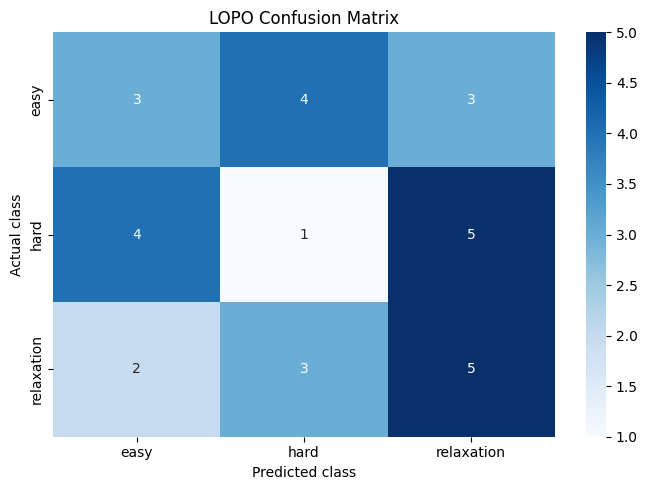


TOP 20 FEATURES BY SELECTION FREQUENCY
        feature  selection_count  selection_frequency
    AF8_d4_mean               10                1.000
    AF8_d4_skew               10                1.000
TP9_d4_kurtosis               10                1.000
    avg_d3_skew               10                1.000
    avg_d4_mean               10                1.000
    avg_d5_skew               10                1.000
AF7_d3_kurtosis                9                0.900
    AF7_d4_skew                9                0.900
    AF8_a5_skew                9                0.900
  avg_d3_median                9                0.900
          θ_AF8                9                0.900
 TP10_d4_median                8                0.800
    TP9_d4_skew                8                0.800
  AF8_d3_median                7                0.700
  AF8_d4_median                7                0.700
   TP10_d4_mean                7                0.700
          β_TP9                7          

In [ ]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import SelectFromModel, SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import LeaveOneGroupOut



class SafeL1Selector(BaseEstimator, TransformerMixin):
    """
    Select features using L1 logistic regression.

    If L1 selects zero features, fall back to SelectKBest.

    Attributes
    ----------
    selected_mask_ : Boolean array
        True for selected features.

    used_fallback_ : bool
        Whether the fallback selector was used.
    """

    def __init__(self, C=1.0, threshold=1e-5, fallback_k=10):
        self.C = C
        self.threshold = threshold
        self.fallback_k = fallback_k

    def fit(self, X, y):

        self.l1_selector_ = SelectFromModel(
            LogisticRegression(
                penalty="l1",
                solver="saga",
                C=self.C,
                max_iter=20000,
                random_state=42
            ),
            threshold=self.threshold
        )

        self.l1_selector_.fit(X, y)

        self.selected_mask_ = (
            self.l1_selector_.get_support()
        )

        self.used_fallback_ = not self.selected_mask_.any()

        if self.used_fallback_:

            k = min(self.fallback_k, X.shape[1])

            self.fallback_selector_ = SelectKBest(
                score_func=f_classif,
                k=k
            )

            self.fallback_selector_.fit(X, y)

            self.selected_mask_ = (
                self.fallback_selector_.get_support()
            )

        return self

    def transform(self, X):
        return X[:, self.selected_mask_]

    def get_support(self):
        return self.selected_mask_.copy()



l1_pipeline = Pipeline([

    
    ("imputer", SimpleImputer(strategy="median")),

   
    ("scaler", StandardScaler()),

    
    ("selection", SafeL1Selector(
        C=1.0,
        threshold=1e-5,
        fallback_k=10
    )),

    
    ("classifier", LogisticRegression(
        penalty="l2",
        solver="lbfgs",
        C=1.0,
        max_iter=20000,
        random_state=42
    ))
])


logo = LeaveOneGroupOut()

class_order = ["easy", "hard", "relaxation"]

selected_features_per_fold = []
fold_scores = []
fold_results = []
prediction_results = []

for fold, (train_idx, test_idx) in enumerate(
    logo.split(X, y, groups),
    start=1
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    test_groups = groups.iloc[test_idx]
    test_patient = test_groups.iloc[0]

    print("\n" + "=" * 75)
    print(f"FOLD {fold} | HELD-OUT PATIENT: {test_patient}")
    print("=" * 75)


    l1_pipeline.fit(X_train, y_train)


    selector = l1_pipeline.named_steps["selection"]

    selected_mask = selector.get_support()

    selected_features = X.columns[
        selected_mask
    ].tolist()

    selected_features_per_fold.append(
        selected_features
    )

    print(f"Selected features: {len(selected_features)}")
    print(f"Fallback used: {selector.used_fallback_}")


    y_pred = l1_pipeline.predict(X_test)

    patient_accuracy = accuracy_score(
        y_test, y_pred
    )

    patient_balanced_accuracy = balanced_accuracy_score(
        y_test, y_pred
    )

    fold_scores.append(patient_balanced_accuracy)



    patient_predictions = pd.DataFrame({
        "fold": fold,
        "patient_id": test_groups.to_numpy(),
        "actual_class": y_test.to_numpy(),
        "predicted_class": y_pred
    })

    patient_predictions["correct"] = (
        patient_predictions["actual_class"]
        == patient_predictions["predicted_class"]
    )

    prediction_results.append(patient_predictions)

    print("\nIndividual predictions:")

    print(
        patient_predictions[
            [
                "patient_id",
                "actual_class",
                "predicted_class",
                "correct"
            ]
        ].to_string(index=False)
    )

    print("\nPer-class accuracy for this patient:")

    patient_class_results = {}

    for class_name in class_order:

        class_mask = (
            y_test.to_numpy() == class_name
        )

        class_total = int(class_mask.sum())

        if class_total == 0:

            class_correct = 0
            class_accuracy = np.nan

            print(
                f"  {class_name}: "
                "N/A (no actual observations)"
            )

        else:

            class_correct = int(
                (
                    y_test.to_numpy()[class_mask]
                    == y_pred[class_mask]
                ).sum()
            )

            class_accuracy = (
                class_correct / class_total
            )

            print(
                f"  {class_name}: "
                f"{class_correct}/{class_total} correct "
                f"({class_accuracy:.1%})"
            )

        patient_class_results[
            f"{class_name}_accuracy"
        ] = class_accuracy

        patient_class_results[
            f"{class_name}_correct"
        ] = class_correct

        patient_class_results[
            f"{class_name}_support"
        ] = class_total


    fold_result = {
        "fold": fold,
        "patient_id": test_patient,
        "n_observations": len(y_test),
        "selected_features": len(selected_features),
        "used_fallback": selector.used_fallback_,
        "accuracy": patient_accuracy,
        "balanced_accuracy": patient_balanced_accuracy
    }

    fold_result.update(patient_class_results)

    fold_results.append(fold_result)

    print(f"\nPatient accuracy: {patient_accuracy:.3f}")
    print(
        f"Patient balanced accuracy: "
        f"{patient_balanced_accuracy:.3f}"
    )


results_df = pd.DataFrame(fold_results)

print("\n" + "=" * 90)
print("PATIENT-WISE CROSS-VALIDATION SUMMARY")
print("=" * 90)

summary_columns = [
    "patient_id",
    "n_observations",
    "accuracy",
    "balanced_accuracy",
    "easy_accuracy",
    "hard_accuracy",
    "relaxation_accuracy",
    "selected_features",
    "used_fallback"
]

print(
    results_df[summary_columns].to_string(
        index=False,
        float_format=lambda value: f"{value:.3f}"
    )
)

print("\nOverall patient-wise metrics:")

print(
    f"Patients evaluated: {len(results_df)}"
)

print(
    f"Mean patient accuracy: "
    f"{results_df['accuracy'].mean():.3f}"
)

print(
    f"Mean patient balanced accuracy: "
    f"{results_df['balanced_accuracy'].mean():.3f}"
)

if len(results_df) > 1:

    print(
        f"SD patient balanced accuracy: "
        f"{results_df['balanced_accuracy'].std(ddof=1):.3f}"
    )


#combine predicions

all_predictions = pd.concat(
    prediction_results,
    ignore_index=True
)

print("\n" + "=" * 75)
print("ALL HELD-OUT PATIENT PREDICTIONS")
print("=" * 75)

print(
    all_predictions[
        [
            "patient_id",
            "actual_class",
            "predicted_class",
            "correct"
        ]
    ].to_string(index=False)
)


print("\n" + "=" * 75)
print("OVERALL CLASSIFICATION REPORT")
print("=" * 75)

print(
    classification_report(
        all_predictions["actual_class"],
        all_predictions["predicted_class"],
        labels=class_order,
        target_names=[
            "Easy",
            "Hard",
            "Relaxation"
        ],
        zero_division=0,
        digits=3
    )
)


cm = confusion_matrix(
    all_predictions["actual_class"],
    all_predictions["predicted_class"],
    labels=class_order
)

cm_df = pd.DataFrame(
    cm,
    index=class_order,
    columns=class_order
)

print("\nConfusion matrix:")
print("Rows = actual class; columns = predicted class")
print(cm_df)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("LOPO Confusion Matrix")

plt.tight_layout()
plt.show()


feature_counts = Counter(
    feature
    for fold_features in selected_features_per_fold
    for feature in fold_features
)

feature_frequency = pd.DataFrame(
    feature_counts.items(),
    columns=[
        "feature",
        "selection_count"
    ]
)

feature_frequency["selection_frequency"] = (
    feature_frequency["selection_count"]
    / len(selected_features_per_fold)
)

feature_frequency = feature_frequency.sort_values(
    ["selection_frequency", "feature"],
    ascending=[False, True]
).reset_index(drop=True)

print("\n" + "=" * 75)
print("TOP 20 FEATURES BY SELECTION FREQUENCY")
print("=" * 75)

print(
    feature_frequency.head(20).to_string(
        index=False,
        float_format=lambda value: f"{value:.3f}"
    )
)


results_df.to_csv(
    "EEG_L1_patient_summary.csv",
    index=False
)

all_predictions.to_csv(
    "EEG_L1_patient_predictions.csv",
    index=False
)

feature_frequency.to_csv(
    "EEG_L1_feature_stability.csv",
    index=False
)

cm_df.to_csv(
    "EEG_L1_confusion_matrix.csv"
)

print("\nSaved output files:")
print("- EEG_L1_patient_summary.csv")
print("- EEG_L1_patient_predictions.csv")
print("- EEG_L1_feature_stability.csv")
print("- EEG_L1_confusion_matrix.csv")


## Hyperparameter tuning

In [ ]:

import numpy as np
import pandas as pd
import warnings

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)


# Use semantic features rather than features_after_corr.
# The global correlation filter was calculated before CV.
X = all_data[semantic_features].copy()
X = X.apply(pd.to_numeric, errors="coerce")

y = all_data["task_label"].copy()
groups = all_data["patient_id"].copy()

class_order = ["easy", "hard", "relaxation"]

print("Dataset shape:", X.shape)
print("Number of patients:", groups.nunique())
print("\nObservations per patient:")
print(all_data.groupby("patient_id").size())

print("\nClass distribution:")
print(y.value_counts())


pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler()),

    ("selection", SafeL1Selector(
        C=0.3,
        threshold=1e-5,
        fallback_k=10
    )),

    ("classifier", LogisticRegression(
        penalty="l2",
        solver="lbfgs",
        max_iter=20000,
        random_state=42
    ))
])


param_grid = {
    "selection__C": [0.03, 0.3, 3.0],
    "selection__fallback_k": [5, 10],

    "classifier__C": [0.01, 0.1, 1.0, 10.0],
    "classifier__class_weight": [None, "balanced"]
}

# 3 x 2 x 4 x 2 = 48 combinations.
print("\nHyperparameter combinations:", 48)


outer_cv = LeaveOneGroupOut()
inner_cv = LeaveOneGroupOut()

outer_results = []
all_predictions = []
best_params_per_patient = []
feature_selections = []

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y, groups),
    start=1
):
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    groups_train = groups.iloc[train_idx]
    groups_test = groups.iloc[test_idx]

    held_out_patient = groups_test.iloc[0]

    print("\n" + "=" * 75)
    print(f"OUTER FOLD {fold}: PATIENT {held_out_patient}")
    print("=" * 75)

    # Inner CV tunes parameters using training patients only.
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="balanced_accuracy",
        cv=inner_cv,
        refit=True,
        n_jobs=-1,
        error_score="raise",
        return_train_score=False
    )

    # groups_train ensures inner CV also holds out entire patients.
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message="The max_iter was reached"
        )
        search.fit(
            X_train,
            y_train,
            groups=groups_train
        )

    # Best pipeline is refitted on all outer training data.
    best_model = search.best_estimator_

    y_pred = best_model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    balanced_acc = balanced_accuracy_score(y_test, y_pred)

    selector = best_model.named_steps["selection"]
    selected_mask = selector.get_support()

    selected_names = X.columns[
        selected_mask
    ].tolist()

    feature_selections.append({
        "patient_id": held_out_patient,
        "features": selected_names
    })

    best_params_per_patient.append({
        "patient_id": held_out_patient,
        "inner_best_balanced_accuracy": search.best_score_,
        "best_params": search.best_params_
    })

    outer_results.append({
        "patient_id": held_out_patient,
        "n_observations": len(y_test),
        "accuracy": accuracy,
        "balanced_accuracy": balanced_acc,
        "selected_features": len(selected_names),
        "used_fallback": selector.used_fallback_
    })

    fold_predictions = pd.DataFrame({
        "patient_id": groups_test.to_numpy(),
        "actual_class": y_test.to_numpy(),
        "predicted_class": y_pred
    })

    fold_predictions["correct"] = (
        fold_predictions["actual_class"]
        == fold_predictions["predicted_class"]
    )

    all_predictions.append(fold_predictions)

    print("Best inner-CV balanced accuracy:",
          round(search.best_score_, 3))
    print("Best parameters:", search.best_params_)
    print("Selected features:", len(selected_names))
    print("Used fallback:", selector.used_fallback_)
    print("Held-out accuracy:", round(accuracy, 3))
    print("Held-out balanced accuracy:", round(balanced_acc, 3))
    print("\nPredictions:")
    print(fold_predictions.to_string(index=False))



results_df = pd.DataFrame(outer_results)
predictions_df = pd.concat(
    all_predictions,
    ignore_index=True
)

print("\n" + "=" * 75)
print("NESTED LOPO RESULTS")
print("=" * 75)

print(results_df.to_string(
    index=False,
    float_format=lambda v: f"{v:.3f}"
))

print("\nMean patient accuracy:",
      round(results_df["accuracy"].mean(), 3))

print("Mean patient balanced accuracy:",
      round(results_df["balanced_accuracy"].mean(), 3))

print("SD patient balanced accuracy:",
      round(results_df["balanced_accuracy"].std(ddof=1), 3))

print("\nOverall classification report:")
print(classification_report(
    predictions_df["actual_class"],
    predictions_df["predicted_class"],
    labels=class_order,
    target_names=["Easy", "Hard", "Relaxation"],
    zero_division=0,
    digits=3
))

cm = confusion_matrix(
    predictions_df["actual_class"],
    predictions_df["predicted_class"],
    labels=class_order
)

print("\nConfusion matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(
    cm,
    index=class_order,
    columns=class_order
))


# Each outer test fold is compared with a classifier
# trained on that fold's training data only.
baseline_predictions = []

for train_idx, test_idx in outer_cv.split(X, y, groups):
    dummy = DummyClassifier(strategy="most_frequent")

    dummy.fit(X.iloc[train_idx], y.iloc[train_idx])

    pred = dummy.predict(X.iloc[test_idx])

    baseline_predictions.extend(pred)

print("\nMajority-class baseline accuracy:",
      round(accuracy_score(y, baseline_predictions), 3))

print("Majority-class baseline balanced accuracy:",
      round(balanced_accuracy_score(y, baseline_predictions), 3))


results_df.to_csv(
    "EEG_nested_LOPO_summary.csv", index=False
)

predictions_df.to_csv(
    "EEG_nested_LOPO_predictions.csv", index=False
)

pd.DataFrame(best_params_per_patient).to_csv(
    "EEG_nested_LOPO_best_parameters.csv", index=False
)

print("\nSaved:")
print("- EEG_nested_LOPO_summary.csv")
print("- EEG_nested_LOPO_predictions.csv")
print("- EEG_nested_LOPO_best_parameters.csv")


Dataset shape: (30, 133)
Number of patients: 10

Observations per patient:
patient_id
140    3
141    3
257    3
260    3
313    3
362    3
404    3
437    3
446    3
491    3
dtype: int64

Class distribution:
easy          10
hard          10
relaxation    10
Name: task_label, dtype: int64

Hyperparameter combinations: 48

OUTER FOLD 1: PATIENT 140
Best inner-CV balanced accuracy: 0.444
Best parameters: {'classifier__C': 0.01, 'classifier__class_weight': None, 'selection__C': 0.03, 'selection__fallback_k': 5}
Selected features: 5
Used fallback: True
Held-out accuracy: 0.667
Held-out balanced accuracy: 0.667

Predictions:
patient_id actual_class predicted_class  correct
       140         easy            easy     True
       140         hard            hard     True
       140   relaxation            easy    False

OUTER FOLD 2: PATIENT 141
Best inner-CV balanced accuracy: 0.444
Best parameters: {'classifier__C': 0.01, 'classifier__class_weight': None, 'selection__C': 0.3, 'selection__

In [ ]:


print("\n" + "=" * 90)
print("BEST HYPERPARAMETERS FOR EACH OUTER FOLD")
print("=" * 90)

best_params_df = pd.DataFrame(best_params_per_patient)

for _, row in best_params_df.iterrows():
    print(f"\nHeld-out patient: {row['patient_id']}")
    print(
        "Best inner-CV balanced accuracy:",
        f"{row['inner_best_balanced_accuracy']:.3f}"
    )

    for param, value in row["best_params"].items():
        print(f"  {param}: {value}")

#most freq selected param combination

# Convert dictionaries into a comparable representation.
param_columns = list(param_grid.keys())

for param in param_columns:
    best_params_df[param] = best_params_df[
        "best_params"
    ].apply(lambda params: params[param])

combination_counts = (
    best_params_df
    .groupby(param_columns, dropna=False)
    .agg(
        frequency=("patient_id", "count"),
        mean_inner_balanced_accuracy=(
            "inner_best_balanced_accuracy", "mean"
        )
    )
    .reset_index()
    .sort_values(
        ["frequency", "mean_inner_balanced_accuracy"],
        ascending=[False, False]
    )
)

print("\n" + "=" * 90)
print("MOST FREQUENTLY SELECTED HYPERPARAMETER COMBINATION")
print("=" * 90)

if not combination_counts.empty:
    top_combination = combination_counts.iloc[0]

    print(
        f"\nSelected in {int(top_combination['frequency'])} "
        f"of {len(best_params_df)} outer folds"
    )

    print(
        "Mean inner-CV balanced accuracy:",
        f"{top_combination['mean_inner_balanced_accuracy']:.3f}"
    )

    print("\nHyperparameters:")

    for param in param_columns:
        print(f"  {param}: {top_combination[param]}")

print("\n" + "=" * 90)
print("HYPERPARAMETER COMBINATION FREQUENCIES")
print("=" * 90)

print(
    combination_counts.to_string(
        index=False,
        float_format=lambda value: f"{value:.3f}"
    )
)

# Save a readable CSV containing one row per outer fold.
best_params_df.drop(
    columns=["best_params"]
).to_csv(
    "EEG_nested_LOPO_best_parameters_detailed.csv",
    index=False
)

print(
    "\nSaved: EEG_nested_LOPO_best_parameters_detailed.csv"
)



BEST HYPERPARAMETERS FOR EACH OUTER FOLD

Held-out patient: 140
Best inner-CV balanced accuracy: 0.444
  classifier__C: 0.01
  classifier__class_weight: None
  selection__C: 0.03
  selection__fallback_k: 5

Held-out patient: 141
Best inner-CV balanced accuracy: 0.444
  classifier__C: 0.01
  classifier__class_weight: None
  selection__C: 0.3
  selection__fallback_k: 5

Held-out patient: 257
Best inner-CV balanced accuracy: 0.407
  classifier__C: 0.1
  classifier__class_weight: None
  selection__C: 0.03
  selection__fallback_k: 10

Held-out patient: 260
Best inner-CV balanced accuracy: 0.407
  classifier__C: 0.01
  classifier__class_weight: None
  selection__C: 0.03
  selection__fallback_k: 5

Held-out patient: 313
Best inner-CV balanced accuracy: 0.519
  classifier__C: 0.1
  classifier__class_weight: None
  selection__C: 0.03
  selection__fallback_k: 10

Held-out patient: 362
Best inner-CV balanced accuracy: 0.370
  classifier__C: 0.01
  classifier__class_weight: None
  selection__C: 0